In [ ]:

from __future__ import annotations

import operator
import os
from typing import TypedDict, List, Annotated  # annontated attach extra metadata

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send  #

from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage


import psycopg  # allow python to communicate with PostgreServer
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver

from dotenv import load_dotenv

load_dotenv()

# Use Send when you want LangGraph to create tasks dynamically—
# for example, when one research request needs several independent AI agents to work on different topics.

True

In [4]:
# loads database url we have to make a function
def get_database_url():
    database_url = os.getenv("DATABASE_URL")

    if not database_url:
        raise ValueError(
            "DATABASE_URL is missing.Please add your Neon Postgres External Database URL"
        )

    # if database url is present
    if "sslmode=" not in database_url:
        separator = "&" if "?" in database_url else "?"
        database_url = f"{database_url}{separator}sslmode=require"  # Connect to PostgreSQL only if the connection is encrypted."

    return database_url


    # SSL --> Connect Python with postgres and ssl=require do encryption
    # SSL/TLS protects data while it travels between your application and the database. 
    # It does not encrypt every database record at rest, and require alone does not fully verify the server's identity.

In [ ]:
GROQ_API_KEY = os.getenv("GROQ_API_KEY")
if not GROQ_API_KEY:
    raise ValueError("GROQ_API_KEY is missing. Please add it to your .env file.")

In [ ]:
# pydantic Class
class Task(BaseModel):
    id:int
    title:str
    brief:str = Field(...,description="What-to-cover")

In [10]:
# pydantic class
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]

In [ ]:
class State(TypedDict):
    topic: str
    plan: Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str],operator.add]  #tells LangGraph to collect and join the blog sections written by different worker agents into one list.
    final:str

In [12]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=GROQ_API_KEY 
)

In [ ]:
# this function will create plan
def orchestrator(state: State) -> dict:
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content="Create a blog plan with 5-7 sections on the following topic."
            ),
            HumanMessage(
                content=f"Topic: {state['topic']}"
            ),
        ]
    )

    return {"plan": plan}


In [ ]:
# for 4 plan 4 workers/agents will be created here
# and this function will automatically create number of agents required like if 4 plan so 4 agents it will create
def fanout(state: State):
    return [Send("worker",{"task":task,"topic": state["topic"],"plan":state["plan"]})
            for task in state["plan"].tasks]


# worker is a node and it will generated subsection of blog

In [16]:
def worker(payload: dict) -> dict:

    # payload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    blog_title = plan.blog_title

    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [35]:
from pathlib import Path

def reducer(state: State) -> dict:
    
    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # ---- save to file ----
    filename = title.lower().replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [27]:
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

In [28]:
# =========================
# PostgreSQL Checkpointer
# =========================
DATABASE_URL = get_database_url()

_conn = psycopg.connect(
    DATABASE_URL,
    autocommit=True,
    row_factory=dict_row
)

checkpointer = PostgresSaver(_conn)
checkpointer.setup()

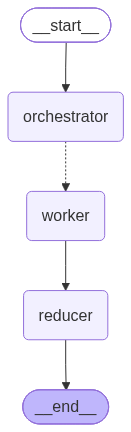

In [20]:
app = g.compile(checkpointer=checkpointer)

app

In [32]:
config = {
        "configurable": {
            "thread_id": "test_thread_id"
        }
    }

In [36]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []}, config=config)

OperationalError: the connection is closed

In [38]:
out

{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Demystifying Self-Attention: The Core of Modern Deep Learning', tasks=[Task(id=1, title='Introduction – Why Self-Attention Matters', brief='Set the stage by explaining the rise of attention mechanisms, their impact on NLP and beyond, and the goal of the blog.'), Task(id=2, title='What Is Self-Attention? Conceptual Overview', brief='Define self-attention in plain language, contrast it with traditional sequence models, and introduce key terminology (queries, keys, values).'), Task(id=3, title='The Mathematics Behind Self-Attention', brief='Walk through the core equations: dot‑product attention, scaling, softmax, and the weighted sum. Include a simple numeric example.'), Task(id=4, title='Self-Attention in the Transformer Architecture', brief='Explain how self‑attention layers are stacked with feed‑forward networks, multi‑head attention, positional encodings, and residual connections.'), Task(id=5, title='Benefits, Limi